# Semantic Grounding

Computing semantic similarity scores...
------------------------------------------------------------
Processed 100/2826 samples...
Processed 200/2826 samples...
Processed 300/2826 samples...
Processed 400/2826 samples...
Processed 500/2826 samples...
Processed 600/2826 samples...
Processed 700/2826 samples...
Processed 800/2826 samples...
Processed 900/2826 samples...
Processed 1000/2826 samples...
Processed 1100/2826 samples...
Processed 1200/2826 samples...
Processed 1300/2826 samples...
Processed 1400/2826 samples...
Processed 1500/2826 samples...
Processed 1600/2826 samples...
Processed 1700/2826 samples...
Processed 1800/2826 samples...
Processed 1900/2826 samples...
Processed 2000/2826 samples...
Processed 2100/2826 samples...
Processed 2200/2826 samples...
Processed 2300/2826 samples...
Processed 2400/2826 samples...
Processed 2500/2826 samples...
Processed 2600/2826 samples...
Processed 2700/2826 samples...
Processed 2800/2826 samples...

Total samples with valid data: 2826
Pos

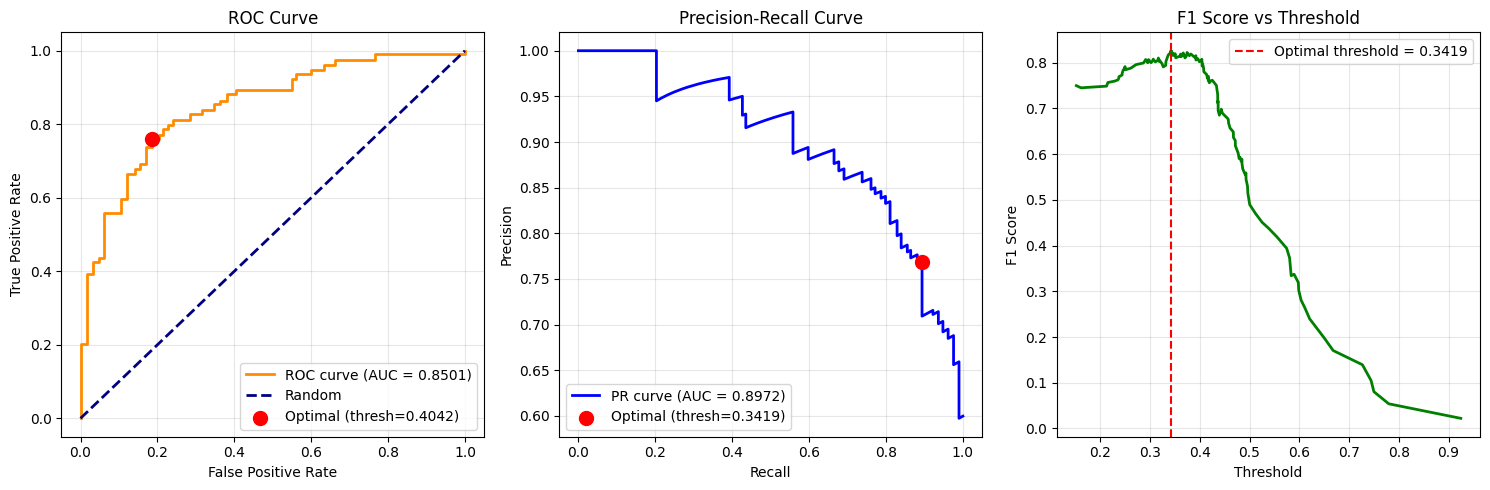


RECOMMENDATION:
Use threshold = 0.3419 (optimized for F1 score)
Median relatedness score: 0.408
Min relatedness score: 0.152
Max relatedness score: 0.925


In [ ]:
from sentence_transformers import SentenceTransformer
import torch
import numpy as np
import json
import os
from sklearn.metrics import roc_curve, auc, precision_recall_curve, f1_score
import matplotlib.pyplot as plt

os.environ["CUDA_VISIBLE_DEVICES"] = "0"

model = SentenceTransformer("all-MiniLM-L6-v2")

# Load the JSON data
with open('./data/gemini_reasoning_eval_all.json', 'r') as f:
    eval_data = json.load(f)

# Initialize lists to store scores and labels
relatedness_scores = []
ground_truth_labels = []

print("Computing semantic similarity scores...")
print("-" * 60)

for i, item in enumerate(eval_data):
    if 'riskVisualIndicator' in item and 'decision_items' in item and 'eval' in item:
        risk_visual = item['riskVisualIndicator']
        decision_items = item['decision_items']
        
        if len(risk_visual) > 0 and len(decision_items) > 0:
            # Encode the risk visual indicators and risk items
            visual_embeddings = model.encode_document(risk_visual)
            items_embeddings = model.encode_query(decision_items)
            
            # Calculate cosine similarities between all pairs
            similarity_matrix = model.similarity(items_embeddings, visual_embeddings)
            
            # For each risk item, find its maximum similarity to any visual indicator
            max_similarities = torch.max(similarity_matrix, dim=1)[0]
            
            # Calculate overall relatedness score (average of max similarities)
            relatedness_score = torch.mean(max_similarities).item()
            
            relatedness_scores.append(relatedness_score)
            ground_truth_labels.append(item['eval'])
            
            if (i + 1) % 100 == 0:
                print(f"Processed {i+1}/{len(eval_data)} samples...")
        
        else:
            unrelated_counts.append(0)
            relatedness_scores.append(0)
            missed_items_per_sample.append(0)
            ground_truth_labels.append(item['eval'])

print(f"\nTotal samples with valid data: {len(relatedness_scores)}")
print(f"Positive samples (eval=1): {sum(ground_truth_labels)}")
print(f"Negative samples (eval=0): {len(ground_truth_labels) - sum(ground_truth_labels)}")
print("-" * 60)

# Convert to numpy arrays
y_true = np.array(ground_truth_labels)
y_scores = np.array(relatedness_scores)

# Compute ROC curve and AUC
fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# Compute Precision-Recall curve
precision, recall, pr_thresholds = precision_recall_curve(y_true, y_scores)
pr_auc = auc(recall, precision)

# Find optimal threshold using Youden's J statistic (ROC curve)
j_scores = tpr - fpr
optimal_idx_roc = np.argmax(j_scores)
optimal_threshold_roc = roc_thresholds[optimal_idx_roc]

# Find optimal threshold using F1 score
f1_scores = []
for thresh in pr_thresholds:
    y_pred = (y_scores >= thresh).astype(int)
    f1 = f1_score(y_true, y_pred)
    f1_scores.append(f1)

optimal_idx_f1 = np.argmax(f1_scores)
optimal_threshold_f1 = pr_thresholds[optimal_idx_f1]

print("\nROC Curve Analysis:")
print(f"  ROC AUC: {roc_auc:.4f}")
print(f"  Optimal threshold (Youden's J): {optimal_threshold_roc:.4f}")
print(f"  TPR at optimal: {tpr[optimal_idx_roc]:.4f}")
print(f"  FPR at optimal: {fpr[optimal_idx_roc]:.4f}")

print("\nPrecision-Recall Analysis:")
print(f"  PR AUC: {pr_auc:.4f}")
print(f"  Optimal threshold (F1): {optimal_threshold_f1:.4f}")
print(f"  Max F1 score: {f1_scores[optimal_idx_f1]:.4f}")
print(f"  Precision at optimal: {precision[optimal_idx_f1]:.4f}")
print(f"  Recall at optimal: {recall[optimal_idx_f1]:.4f}")

# Plot ROC curve
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
plt.scatter(fpr[optimal_idx_roc], tpr[optimal_idx_roc], color='red', s=100, 
            label=f'Optimal (thresh={optimal_threshold_roc:.4f})', zorder=5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

# Plot Precision-Recall curve
plt.subplot(1, 3, 2)
plt.plot(recall, precision, color='blue', lw=2, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.scatter(recall[optimal_idx_f1], precision[optimal_idx_f1], color='red', s=100,
            label=f'Optimal (thresh={optimal_threshold_f1:.4f})', zorder=5)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)

# Plot F1 scores vs thresholds
plt.subplot(1, 3, 3)
plt.plot(pr_thresholds, f1_scores, color='green', lw=2)
plt.axvline(optimal_threshold_f1, color='red', linestyle='--', 
            label=f'Optimal threshold = {optimal_threshold_f1:.4f}')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("RECOMMENDATION:")
print(f"Use threshold = {optimal_threshold_f1:.4f} (optimized for F1 score)")
print("=" * 60)
print(f"Median relatedness score: {np.median(relatedness_scores):.3f}")
print(f"Min relatedness score: {np.min(relatedness_scores):.3f}")
print(f"Max relatedness score: {np.max(relatedness_scores):.3f}")

# precision and recall curve, auc

In [ ]:
from sentence_transformers import SentenceTransformer
import torch
import numpy as np
import json
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "0"

model = SentenceTransformer("all-MiniLM-L6-v2")

# Load the JSON data
with open('./data/gemini_reasoning_eval_all.json', 'r') as f:
    eval_data = json.load(f)

# Initialize lists to store all similarities and unrelated counts
all_similarities = []
unrelated_counts = []
relatedness_scores = []
missed_items_per_sample = []

# Set threshold for determining if items are unrelated
threshold = 0.35

print("Analyzing semantic similarity between risk visual indicators and risk items...")
print(f"Using threshold: {threshold}")
print("-" * 60)

for i, item in enumerate(eval_data):
    if 'riskVisualIndicator' in item and 'decision_items' in item:
        risk_visual = item['riskVisualIndicator']
        decision_items = item['decision_items']
        
        if len(risk_visual) > 0 and len(decision_items) > 0:
            # Encode the risk visual indicators and risk items
            visual_embeddings = model.encode_document(risk_visual)
            items_embeddings = model.encode_query(decision_items)
            
            # Calculate cosine similarities between all pairs
            similarity_matrix = model.similarity(items_embeddings, visual_embeddings)
            
            # For each risk item, find its maximum similarity to any visual indicator
            max_similarities = torch.max(similarity_matrix, dim=1)[0]
            
            # Count items below threshold (unrelated)
            unrelated_count = torch.sum(max_similarities < threshold).item()
            
            # Calculate missed items (items that didn't have any visual indicator passing threshold)
            max_similarities_t = torch.max(similarity_matrix.T, dim=1)[0]
            missed_items = torch.sum(max_similarities_t < threshold).item()
            
            # Calculate overall relatedness score (average of max similarities)
            relatedness_score = torch.mean(max_similarities).item()
            
            all_similarities.extend(max_similarities.tolist())
            unrelated_counts.append(unrelated_count)
            relatedness_scores.append(relatedness_score)
            missed_items_per_sample.append(missed_items)
            
            print(f"Sample {i+1}:")
            print(f"  Risk items: {len(decision_items)}")
            print(f"  Visual indicators: {len(risk_visual)}")
            print(f"  Unrelated items (< {threshold}): {unrelated_count}")
            print(f"  Missed items (no visual above threshold): {missed_items}")
            print(f"  Relatedness score: {relatedness_score:.3f}")
            print()
        else:
            all_similarities.append([0])
            unrelated_counts.append(0)
            relatedness_scores.append(0)
            missed_items_per_sample.append(0)
        
        print(max_similarities)

# Overall statistics
print("Overall Analysis:")
print("-" * 30)
print(f"Total samples analyzed: {len(relatedness_scores)}")
print(f"Average unrelated items per sample: {np.mean(unrelated_counts):.2f}")
print(f"Average missed items per sample: {np.mean(missed_items_per_sample):.2f}")
print(f"Average relatedness score: {np.mean(relatedness_scores):.3f}")
print(f"Median relatedness score: {np.median(relatedness_scores):.3f}")
print(f"Min relatedness score: {np.min(relatedness_scores):.3f}")
print(f"Max relatedness score: {np.max(relatedness_scores):.3f}")

Analyzing semantic similarity between risk visual indicators and risk items...
Using threshold: 0.35
------------------------------------------------------------
Sample 1:
  Risk items: 5
  Visual indicators: 2
  Unrelated items (< 0.35): 3
  Missed items (no visual above threshold): 1
  Relatedness score: 0.336

tensor([0.5054, 0.3320, 0.3859, 0.2798, 0.1747])
Sample 2:
  Risk items: 10
  Visual indicators: 3
  Unrelated items (< 0.35): 6
  Missed items (no visual above threshold): 0
  Relatedness score: 0.332

tensor([0.2247, 0.3409, 0.2694, 0.1989, 0.2186, 0.2545, 0.4406, 0.5163, 0.4142,
        0.4372])
Sample 3:
  Risk items: 3
  Visual indicators: 3
  Unrelated items (< 0.35): 1
  Missed items (no visual above threshold): 1
  Relatedness score: 0.635

tensor([0.7133, 0.1903, 1.0000])
Sample 4:
  Risk items: 9
  Visual indicators: 4
  Unrelated items (< 0.35): 5
  Missed items (no visual above threshold): 2
  Relatedness score: 0.350

tensor([0.5195, 0.4036, 0.3617, 0.3008, 0.1357

Plot saved as 'relatedness_scores_distribution.png'


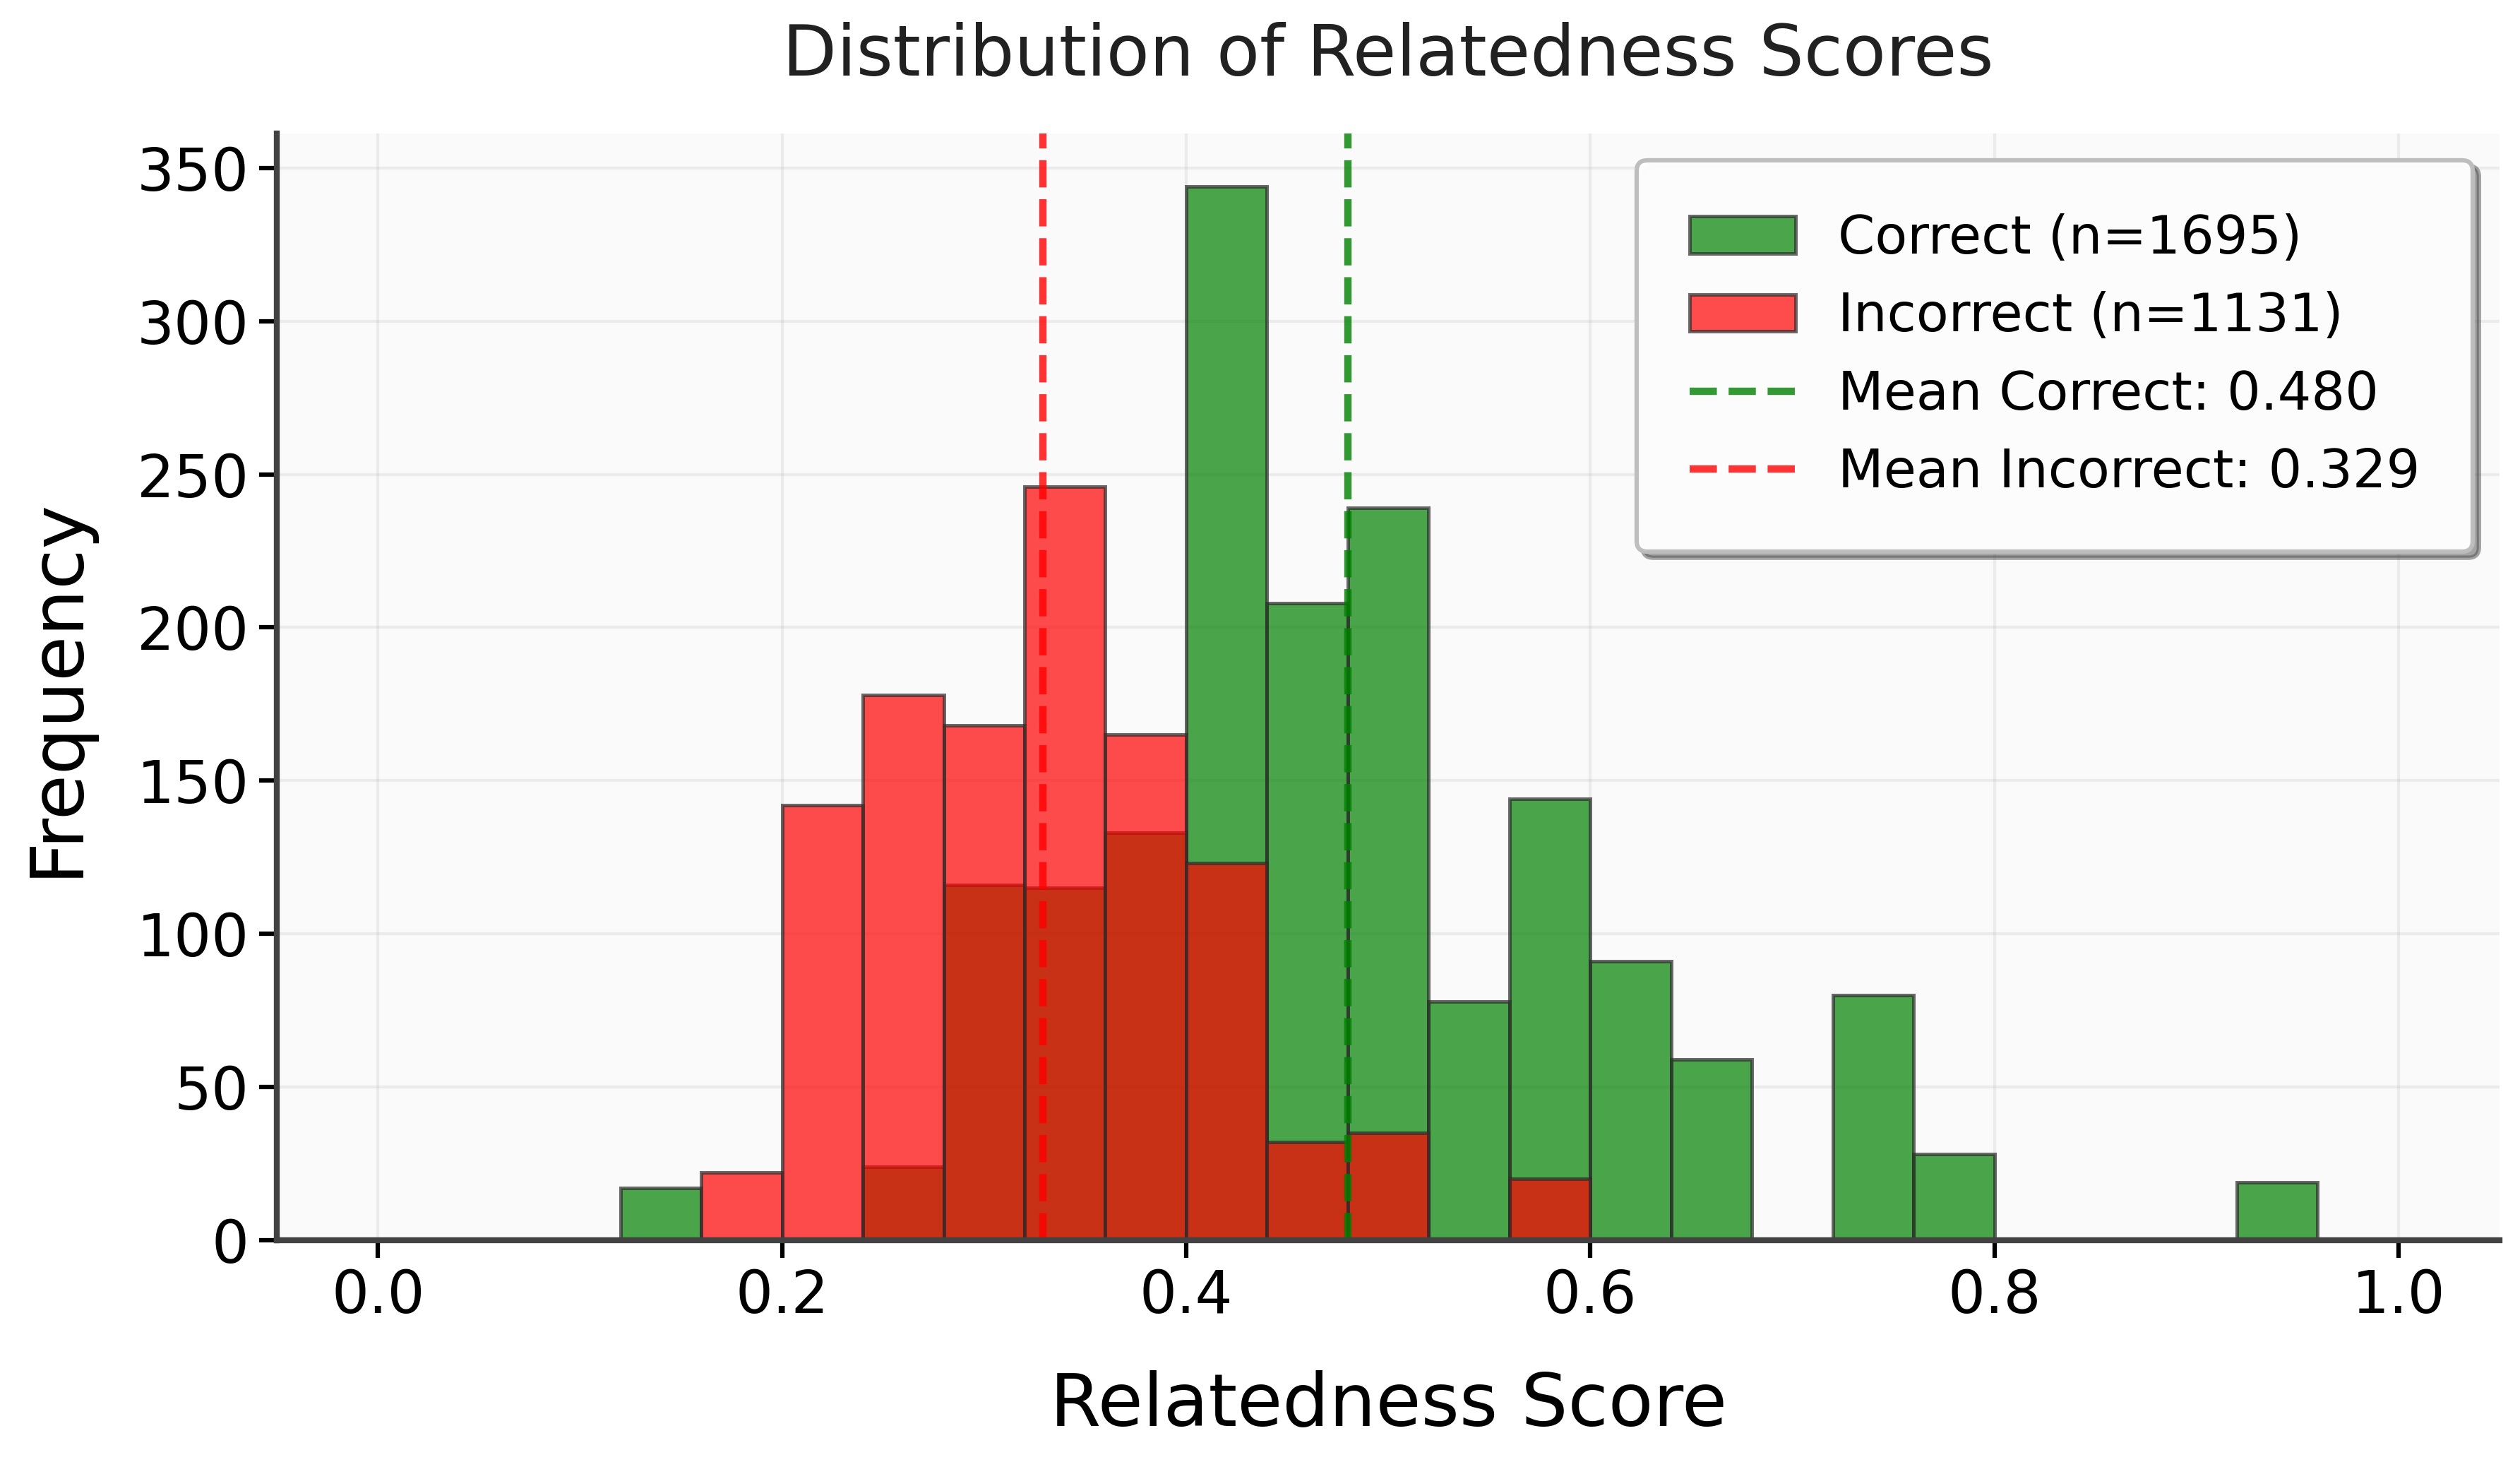

Statistical Summary:
----------------------------------------
  Mean relatedness score: 0.480
  Std relatedness score: 0.130
  Mean relatedness score: 0.329
  Std relatedness score: 0.082

STATISTICAL SIGNIFICANCE TEST:
Independent t-test:
  t-statistic: 34.6357
  p-value: 0.0000

Mann-Whitney U test (non-parametric):
  U-statistic: 1629601.0000
  p-value: 0.0000

Interpretation (α = 0.05):
  ✓ The difference IS statistically significant (p < 0.05)

Effect size (Cohen's d): 1.3298
  (large effect)


In [11]:
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
from matplotlib.patches import Rectangle

# Extract eval scores for samples that were analyzed
eval_scores = []
analyzed_relatedness_scores = []

for i, item in enumerate(eval_data):
    if 'riskVisualIndicator' in item and 'decision_items' in item and 'eval' in item:
        risk_visual = item['riskVisualIndicator']
        decision_items = item['decision_items']
        
        eval_scores.append(item['eval'])
        analyzed_relatedness_scores.append(relatedness_scores[i])

# Separate correct (eval=1) and incorrect (eval=0) predictions
correct_scores = [score for score, eval_val in zip(analyzed_relatedness_scores, eval_scores) if eval_val == 1]
incorrect_scores = [score for score, eval_val in zip(analyzed_relatedness_scores, eval_scores) if eval_val == 0]


# Create the plot with improved aesthetics
fig, ax = plt.subplots(figsize=(12, 7), dpi=300)

# Create histogram with better styling - use same bins for both distributions
bins = np.linspace(0, 1, 26)  # 25 bins from 0 to 1, shared across both histograms
plt.hist(correct_scores, bins=bins, alpha=0.7, color='green', 
         label=f'Correct (n={len(correct_scores)})', 
         edgecolor='#2C2C2C', linewidth=1.2)
plt.hist(incorrect_scores, bins=bins, alpha=0.7, color='red', 
         label=f'Incorrect (n={len(incorrect_scores)})', 
         edgecolor='#2C2C2C', linewidth=1.2)

plt.xlabel('Relatedness Score', fontsize=25, fontweight='normal', labelpad=15)
plt.ylabel('Frequency', fontsize=25, fontweight='normal', labelpad=15)
plt.title('Distribution of Relatedness Scores', 
          fontsize=24, fontweight='normal', pad=20, color='#212121')
plt.grid(True, alpha=0.2, linestyle='-', linewidth=1, zorder=0)
ax.set_axisbelow(True)

# Set tick font sizes
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
ax.tick_params(axis='both', width=1.5, length=6)

# Add mean lines with better styling
if len(correct_scores) > 0:
    mean_correct = np.mean(correct_scores)
    plt.axvline(mean_correct, color='green', linestyle='--', linewidth=2.5, alpha=0.8, 
                label=f'Mean Correct: {mean_correct:.3f}')
if len(incorrect_scores) > 0:
    mean_incorrect = np.mean(incorrect_scores)
    plt.axvline(mean_incorrect, color='red', linestyle='--', linewidth=2.5, alpha=0.8, 
                label=f'Mean Incorrect: {mean_incorrect:.3f}')

# Clean, modern spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_color('#424242')
ax.spines['bottom'].set_color('#424242')

# Beautiful background
ax.set_facecolor('#FAFAFA')
fig.patch.set_facecolor('white')

# Add legend with improved styling
legend = plt.legend(fontsize=18, framealpha=0.98, loc='upper right', 
                   edgecolor='#BDBDBD', fancybox=True, 
                   shadow=True, frameon=True, borderpad=1)
legend.get_frame().set_linewidth(1.5)

plt.tight_layout()

# Save the plot in high definition
plt.savefig('relatedness_scores_distribution.png', dpi=300, bbox_inches='tight', facecolor='white')
print("Plot saved as 'relatedness_scores_distribution.png'")

plt.show()

# Print statistical summary
print("Statistical Summary:")
print("-" * 40)
if len(correct_scores) > 0:
    print(f"  Mean relatedness score: {np.mean(correct_scores):.3f}")
    print(f"  Std relatedness score: {np.std(correct_scores):.3f}")

if len(incorrect_scores) > 0:
    print(f"  Mean relatedness score: {np.mean(incorrect_scores):.3f}")
    print(f"  Std relatedness score: {np.std(incorrect_scores):.3f}")

# Statistical significance test
print("\n" + "=" * 60)
print("STATISTICAL SIGNIFICANCE TEST:")
print("=" * 60)
if len(correct_scores) > 0 and len(incorrect_scores) > 0:
    # Perform independent t-test
    t_stat, p_value = stats.ttest_ind(correct_scores, incorrect_scores)
    print(f"Independent t-test:")
    print(f"  t-statistic: {t_stat:.4f}")
    print(f"  p-value: {p_value:.4f}")
    
    # Perform Mann-Whitney U test (non-parametric alternative)
    u_stat, p_value_mw = stats.mannwhitneyu(correct_scores, incorrect_scores, alternative='two-sided')
    print(f"\nMann-Whitney U test (non-parametric):")
    print(f"  U-statistic: {u_stat:.4f}")
    print(f"  p-value: {p_value_mw:.4f}")
    
    # Interpretation
    alpha = 0.05
    print(f"\nInterpretation (α = {alpha}):")
    if p_value < alpha:
        print(f"  ✓ The difference IS statistically significant (p < {alpha})")
    else:
        print(f"  ✗ The difference is NOT statistically significant (p >= {alpha})")
    
    # Effect size (Cohen's d)
    pooled_std = np.sqrt(((len(correct_scores)-1)*np.std(correct_scores, ddof=1)**2 + 
                          (len(incorrect_scores)-1)*np.std(incorrect_scores, ddof=1)**2) / 
                         (len(correct_scores) + len(incorrect_scores) - 2))
    cohens_d = (np.mean(correct_scores) - np.mean(incorrect_scores)) / pooled_std
    print(f"\nEffect size (Cohen's d): {cohens_d:.4f}")
    if abs(cohens_d) < 0.2:
        print("  (small effect)")
    elif abs(cohens_d) < 0.5:
        print("  (small to medium effect)")
    elif abs(cohens_d) < 0.8:
        print("  (medium to large effect)")
    else:
        print("  (large effect)")
else:
    print("Insufficient data for statistical testing")
print("=" * 60)

# Reasoning Length Distribution

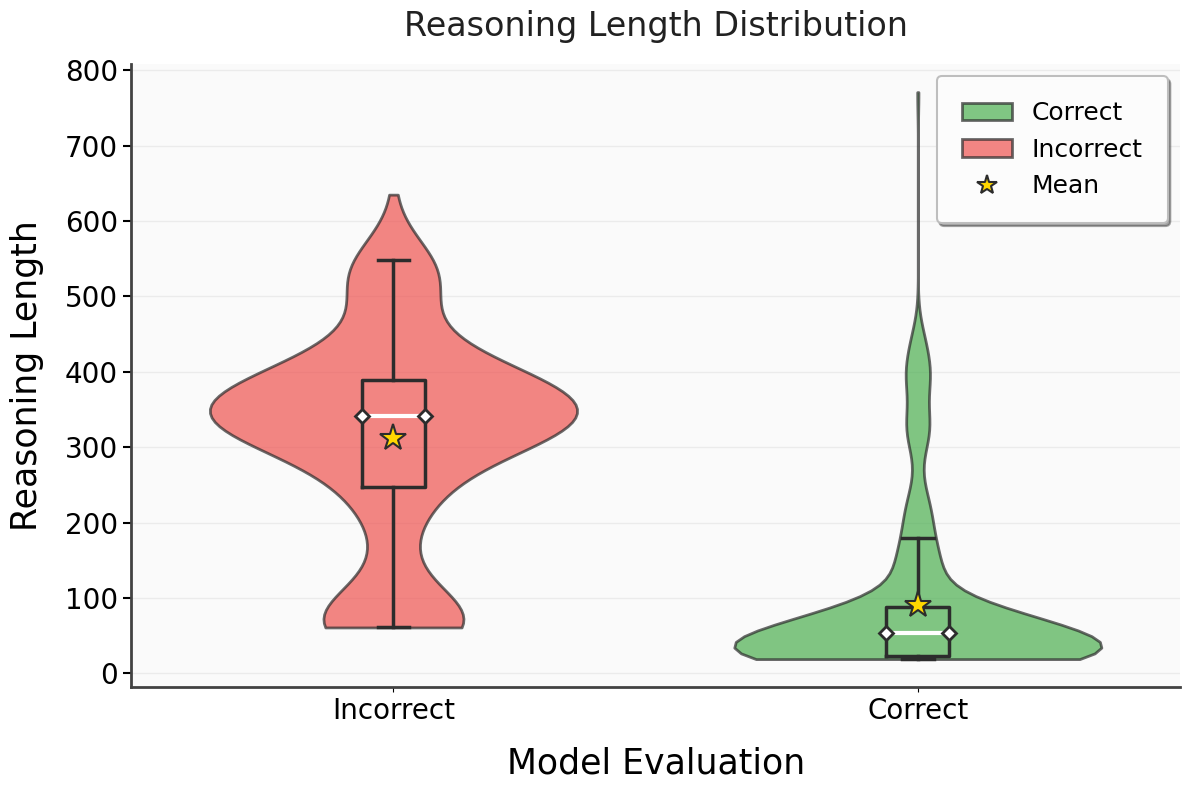

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("./data/reasoning_lengths.csv")

df['eval'] = df.apply(
    lambda row: 1 if str(row['riskLabel']).lower() in str(row['model_output'])[-20:].lower() else 0,
    axis=1
)

# Calculate word count in model_output
df['word_count'] = df['model_output'].apply(lambda x: len(str(x).split()))

# Separate correct and wrong predictions
correct = df[df['eval'] == 1]
# After this line:
wrong = df[df['eval'] == 0]

# Prepare data for violin plot
data = [correct['word_count'].values, wrong['word_count'].values]
positions = [1, 0]  # X-axis positions (1 for correct, 0 for incorrect)

# Create plot with beautiful styling
fig, ax = plt.subplots(figsize=(12, 8), dpi=100)

# Create violin plot
parts = ax.violinplot(data, positions=positions, widths=0.7,
                      showmeans=False, showmedians=False, showextrema=False)

# Color the violins with beautiful colors
colors = ['#4CAF50', '#EF5350']  # Green for correct, Red for incorrect
for pc, color in zip(parts['bodies'], colors):
    pc.set_facecolor(color)
    pc.set_edgecolor('#2C2C2C')
    pc.set_linewidth(2)
    pc.set_alpha(0.7)

# Add box plots overlay for quartiles
bp = ax.boxplot(data, positions=positions, widths=0.12,
                showfliers=False,
                boxprops=dict(color='#2C2C2C', linewidth=2.5),
                whiskerprops=dict(color='#2C2C2C', linewidth=2.5),
                capprops=dict(color='#2C2C2C', linewidth=2.5),
                medianprops=dict(color='white', linewidth=3, marker='D', 
                                markersize=7, markerfacecolor='white', 
                                markeredgecolor='#2C2C2C', markeredgewidth=2))

# Add mean markers
for i, pos in enumerate(positions):
    mean_val = data[i].mean()
    ax.plot(pos, mean_val, marker='*', color='#FFD700', markersize=20, 
            markeredgecolor='#2C2C2C', markeredgewidth=1.5, zorder=5)

# Styling with larger fonts
ax.set_xlabel('Model Evaluation', fontsize=25, fontweight='normal', labelpad=15)
ax.set_ylabel('Reasoning Length', fontsize=25, fontweight='normal', labelpad=15)
ax.set_title('Reasoning Length Distribution', 
             fontsize=24, fontweight='normal', pad=20, color='#212121')

# Set x-axis
ax.set_xticks([1, 0])
ax.set_xticklabels(['Correct', 'Incorrect'], fontsize=20, fontweight='normal')

# Set y-axis with better formatting
ax.tick_params(axis='y', labelsize=20, width=1.5, length=6)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=10))

# Add grid for readability
ax.grid(axis='y', alpha=0.2, linestyle='-', linewidth=1, zorder=0)
ax.set_axisbelow(True)

# Clean, modern spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_color('#424242')
ax.spines['bottom'].set_color('#424242')

# Beautiful background
ax.set_facecolor('#FAFAFA')
fig.patch.set_facecolor('white')

# Add legend
from matplotlib.patches import Rectangle
legend_elements = [
    Rectangle((0, 0), 1, 1, fc='#4CAF50', ec='#2C2C2C', lw=2, alpha=0.7, label='Correct'),
    Rectangle((0, 0), 1, 1, fc='#EF5350', ec='#2C2C2C', lw=2, alpha=0.7, label='Incorrect'),
    plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='#FFD700', 
               markersize=15, markeredgecolor='#2C2C2C', markeredgewidth=1.5, label='Mean', linestyle='None')
]
legend = ax.legend(handles=legend_elements, loc='upper right', fontsize=18, 
                   framealpha=0.98, edgecolor='#BDBDBD', fancybox=True, 
                   shadow=True, frameon=True, borderpad=1)
legend.get_frame().set_linewidth(1.5)

# Adjust layout
plt.tight_layout()

# Save in high definition
plt.savefig('reasoning_length_violin.png', dpi=300, bbox_inches='tight', facecolor='white')

plt.show()
